In [9]:
from ultralytics import YOLO
from pathlib import Path

MODEL_PATH = Path.home() / ".files" / "models" / "yolo11n-pose.pt"

model = YOLO(str(MODEL_PATH))

In [3]:
video_path = "/Users/startup/.files/input/videos/input_video.mp4"

cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    print("Video loaded successfully!")
else:
    print("Error: Unable to load video. Check the video path.")

Video loaded successfully!


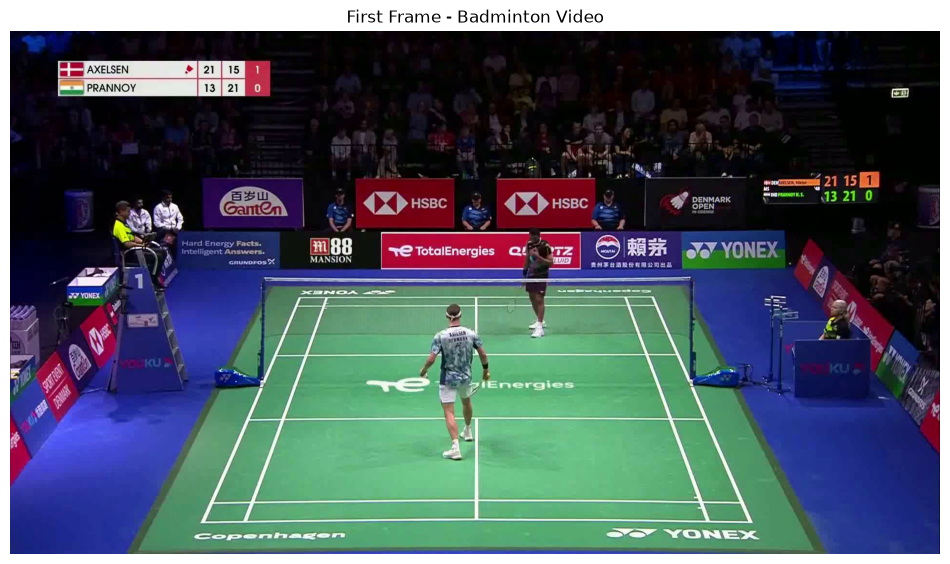

In [4]:
ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 7))
    plt.imshow(frame_rgb)
    plt.title("First Frame - Badminton Video")
    plt.axis("off")
    plt.show()
else:
    print("Unable to read the first frame.")

In [5]:
fps = cap.get(cv2.CAP_PROP_FPS)

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps

print("Video Properties")
print("----------------")
print("Width:", width)
print("Height:", height)
print("FPS:", fps)
print("Total Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")

Video Properties
----------------
Width: 1920
Height: 1080
FPS: 30.0
Total Frames: 538
Duration: 17.93 seconds


In [12]:
# Reset video to the beginning
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Process the complete video
while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    # Run YOLO Pose on the current video frame
    results = model(frame, verbose=False)

    # Draw pose keypoints and skeletons
    annotated_frame = results[0].plot()

    # Display the processed video frame
    cv2.imshow("Badminton - YOLO Pose Detection", annotated_frame)

    # Press Q to stop
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
cap = cv2.VideoCapture(video_path)

while cap.isOpened():

    ret, frame = cap.read()
    if not ret:
        break

    result = model(frame, verbose=False)[0]
    annotated_frame = result.plot()

    if result.keypoints is not None and result.boxes is not None:

        keypoints = result.keypoints.xy.cpu().numpy()
        boxes = result.boxes.xyxy.cpu().numpy()
        confidences = result.keypoints.conf.cpu().numpy()

        players = []

        for i, person in enumerate(keypoints):

            ankles = person[[15, 16]]
            ankle_conf = confidences[i][[15, 16]]

            valid = ankle_conf > 0.3

            if not np.any(valid):
                continue

            foot_y = np.mean(ankles[valid, 1])

            players.append({
                "index": i,
                "foot_y": foot_y,
                "box": boxes[i]
            })

        players.sort(key=lambda p: p["foot_y"])




        labels = ["Upper Player", "Lower Player"]

        for rank, player in enumerate(players[:2]):

            x1, y1, x2, y2 = map(int, player["box"])

            cv2.putText(
                annotated_frame,
                labels[rank],
                (x1, max(y1 - 10, 30)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

    cv2.imshow("Badminton Player Identification", annotated_frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [17]:
import pandas as pd

cap = cv2.VideoCapture(video_path)

player_data = []
frame_number = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    result = model(frame, verbose=False)[0]

    if result.keypoints is not None and result.keypoints.conf is not None:

        keypoints = result.keypoints.xy.cpu().numpy()
        confidences = result.keypoints.conf.cpu().numpy()

        players = []

        for i, person in enumerate(keypoints):

            # Extract left and right ankle coordinates
            left_ankle = person[15]
            right_ankle = person[16]

            # Check ankle confidence
            ankle_conf = confidences[i][[15, 16]]
            valid = ankle_conf > 0.3

            if not np.any(valid):
                continue

            # Calculate average vertical foot position
            ankles = person[[15, 16]]
            foot_y = np.mean(ankles[valid, 1])

            players.append({
                "left_ankle_x": left_ankle[0] if valid[0] else None,
                "left_ankle_y": left_ankle[1] if valid[0] else None,
                "right_ankle_x": right_ankle[0] if valid[1] else None,
                "right_ankle_y": right_ankle[1] if valid[1] else None,
                "average_foot_y": foot_y
            })

        # Sort players by vertical position
        players.sort(key=lambda p: p["average_foot_y"])

        labels = ["Upper Player", "Lower Player"]

        for rank, player in enumerate(players[:2]):

            player_data.append({
                "frame_number": frame_number,
                "player": labels[rank],
                **player
            })

    frame_number += 1

cap.release()

print("Video processing completed!")
print("Total frames processed:", frame_number)
print("Total player records:", len(player_data))

ImportError: C extension: pandas.compat._constants not built. If you want to import pandas from the source directory, you may need to run 'python setup.py build_ext' to build the C extensions first.